[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aranaur/aranaur.rbind.io/blob/main/lectures/kse/MATH840/26autumn/labs/_demo09_uk.ipynb)

# MATH840 — Практика тижня 9: Prophet зблизька, а потім — мудрість середнього

**Не оцінюється.** Дві частини, і через обидві проходить одне питання: *чи справді новий інструмент
кращий за старі?*

**Частина 1 — Prophet по деталях.** Бібліотека Facebook обіцяє багато: кілька сезонів одразу, свята,
зовнішні змінні, тренд, що вміє згинатися. Вмикаємо ці можливості по одній і щоразу перевіряємо
результат проти моделей, які ви вже знаєте.

**Частина 2 — комбінації.** Замість того щоб обирати одну модель-переможницю, усереднюємо кілька. Чому це
працює, коли не працює, і рецепт для сьогоднішньої Lab 8.

| | Історія | Що побачимо | Хв |
|---|---|---|---:|
| 1 | ⚡ Електрика Мельбурна, день за днем | з чого складається Prophet: сезони, свята, температура | 30 |
| 2 | 🍽️ Австралійці їдять поза домом | тренд Prophet і два налаштування, від яких усе залежить | 15 |
| 3 | 🍽️ той самий ряд, чотири моделі | чому середнє прогнозів важко обіграти | 10 |
| 4 | 🏨 76 туристичних регіонів | обрати найкращу модель чи усереднити всі? | 10 |
| 5 | 🍽️ рецепт Lab 8 | комбінація + чесний інтервал, крок за кроком | 20 |

🔮 — здогадка: запишіть її до того, як запустите клітинку. ❓ — питання до аудиторії.

## 0. Налаштування

In [1]:
!pip install -q statsforecast==2.1.1 great_tables prophet

import os
os.environ["NIXTLA_ID_AS_COL"] = "true"
import logging
import warnings
warnings.filterwarnings("ignore")
for name in ("cmdstanpy", "prophet"):
    logging.getLogger(name).setLevel(logging.CRITICAL)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from great_tables import GT, loc, style
from matplotlib.colors import LinearSegmentedColormap, to_hex
from prophet import Prophet
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, AutoETS, AutoTheta, MSTL, SeasonalNaive

plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 120, "display.precision", 3)

BASE = ("https://raw.githubusercontent.com/Aranaur/aranaur.rbind.io/"
        "main/lectures/kse/MATH840/26autumn/data")
COLOURS = {"actual": "#314f4f", "a": "#e64173", "b": "#20B2AA", "c": "#FFA500", "d": "#6A5ACD", "old": "#9aa5a5"}

Три помічники на все заняття. Головний — `backtest`: він приймає **будь-який** прогнозист — функцію, яка
отримує «скільки історії тобі можна бачити» і повертає наступні `h` значень. Тож ETS і Prophet
оцінюються за одним і тим самим правилом.

In [2]:
def backtest(y, forecasters, origins, h, scale, labels=None):
    # MASE of every forecaster from every origin, plus the mean; the forecasts come back for plotting.
    forecasts = {name: [np.asarray(f(e)) for e in origins] for name, f in forecasters.items()}
    table = pd.DataFrame({name: [np.mean(np.abs(y[e:e + h] - fc)) / scale for e, fc in zip(origins, fcs)]
                          for name, fcs in forecasts.items()}, index=labels or origins).T
    table["mean"] = table.mean(axis=1)
    return table, forecasts


def fourier(t, period, K):
    # Fourier terms from Week 5; the period can be any number: 7, 365.25, 52.18.
    return np.column_stack([f(2 * np.pi * k * t / period) for k in range(1, K + 1) for f in (np.sin, np.cos)])


_shade = LinearSegmentedColormap.from_list("shade", ["#bfe0b0", "#ffffff", "#f5b8cb"])


def scoreboard(table, rules=None, decimals=2):
    # Green is better, pink is worse, the best in bold. A rule is "lower", "higher" or a target value.
    df = table.to_frame() if isinstance(table, pd.Series) else table.copy()
    df.index, df.columns = df.index.map(str), df.columns.map(str)
    rules = rules or {c: "lower" for c in df.columns}
    gt = (GT(df.reset_index(names=" "), rowname_col=" ")
          .fmt_number(columns=list(df.select_dtypes("number").columns), decimals=decimals)
          .sub_missing(missing_text=""))
    for c, rule in rules.items():
        v = df[c].astype(float)
        bad = v if rule == "lower" else -v if rule == "higher" else (v - rule).abs()
        lo, hi = bad.min(), bad.max()
        for i, b in enumerate(bad):
            if np.isnan(b):
                continue
            look = [style.fill(color=to_hex(_shade((b - lo) / (hi - lo) if hi > lo else 0.0)))]
            gt = gt.tab_style(style=look + ([style.text(weight="bold")] if b == lo else []),
                              locations=loc.body(columns=c, rows=[i]))
    return gt

# Частина 1. Prophet по деталях

## 1. ⚡ Електрика Мельбурна, день за днем

Ви керуєте енергомережею штату Вікторія. Щоранку вас питають: *скільки електрики знадобиться кожного дня
наступних чотирьох тижнів?* Замало — і доведеться купувати за панічними цінами або вимикати людей.
Забагато — і ви платите за електростанції, що стоять без діла.

Дані: добовий попит за 2012–2014 роки (ГВт·год), максимальна температура дня і календар державних свят.

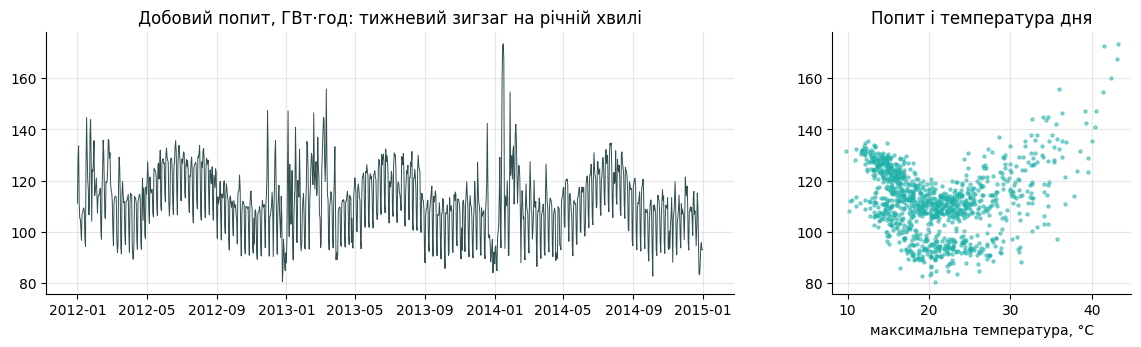

In [3]:
vic = pd.read_csv(f"{BASE}/vic_elec.csv", parse_dates=["ds"])
wide = vic.pivot_table(index="ds", columns="unique_id", values="y")
holiday = vic.query("unique_id == 'Demand'").set_index("ds")["Holiday"].astype(bool)
elec = pd.DataFrame({"y": wide["Demand"].resample("D").sum() / 2e3,      # half-hourly MW -> GWh per day
                     "temp": wide["Temperature"].resample("D").max(),
                     "holiday": holiday.resample("D").max()}).reset_index()
elec["temp2"] = elec["temp"] ** 2

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), width_ratios=[2.3, 1])
axes[0].plot(elec["ds"], elec["y"], color=COLOURS["actual"], linewidth=0.7)
axes[0].set_title("Добовий попит, ГВт·год: тижневий зигзаг на річній хвилі")
axes[1].scatter(elec["temp"], elec["y"], s=5, color=COLOURS["b"], alpha=0.5)
axes[1].set_title("Попит і температура дня")
axes[1].set_xlabel("максимальна температура, °C")
plt.show()

Два сезони одночасно — **тижневий** (вихідні тихі) і **річний** (опалення взимку, кондиціонери влітку) — і
**U-подібний** зв'язок із температурою: і холодні, і спекотні дні підштовхують попит угору.

ETS і сезонна ARIMA вміщують **один** сезон. Prophet створювали саме для таких рядів.

### 1.1 Prophet у п'ять рядків

Prophet не дивиться на вчорашнє значення, як ETS чи ARIMA. Він проводить криву крізь час:

$$y_t = \underbrace{g(t)}_{\text{тренд}} + \underbrace{s(t)}_{\text{сезони}} + \underbrace{h(t)}_{\text{свята}}
+ \underbrace{\beta x_t}_{\text{додаткові змінні}} + \varepsilon_t$$

Кожен сезон — це сума синусів і косинусів, ті самі члени Фур'є з тижня 5. Навчимо модель на всьому до
кінця вересня 2014 і спрогнозуємо жовтень–грудень.

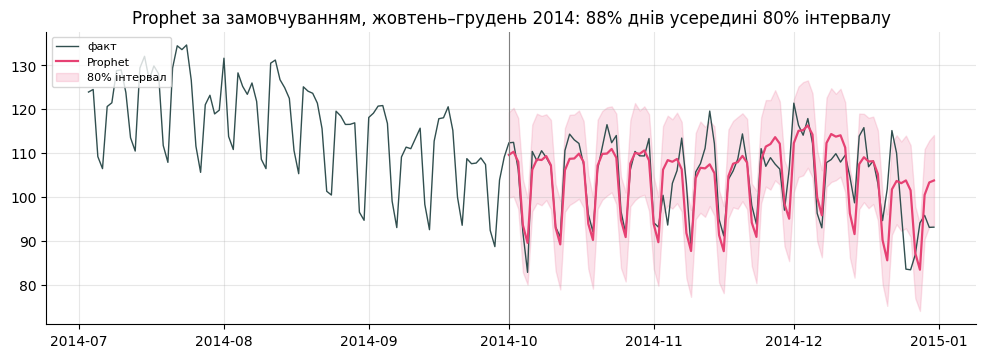

In [4]:
cut = int(elec["ds"].searchsorted(pd.Timestamp("2014-10-01")))
train_e, test_e = elec.iloc[:cut], elec.iloc[cut:]

m = Prophet(daily_seasonality=False)            # weekly and yearly seasons switch on by themselves
m.fit(train_e[["ds", "y"]])
fc = m.predict(test_e[["ds"]])

inside = np.mean((test_e["y"].to_numpy() >= fc["yhat_lower"]) & (test_e["y"].to_numpy() <= fc["yhat_upper"]))
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(elec["ds"].iloc[cut - 90:], elec["y"].iloc[cut - 90:], color=COLOURS["actual"], linewidth=1, label="факт")
ax.plot(fc["ds"], fc["yhat"], color=COLOURS["a"], linewidth=1.6, label="Prophet")
ax.fill_between(fc["ds"], fc["yhat_lower"], fc["yhat_upper"], color=COLOURS["a"], alpha=0.15, label="80% інтервал")
ax.axvline(test_e["ds"].iloc[0], color="grey", linewidth=0.8)
ax.set_title(f"Prophet за замовчуванням, жовтень–грудень 2014: {inside:.0%} днів усередині 80% інтервалу")
ax.legend(loc="upper left", fontsize=8)
plt.show()

### 1.2 Зазирнімо всередину: чого навчився Prophet?

Велика перевага Prophet над ARIMA: кожну частину кривої можна намалювати й прочитати.

🔮 **Спершу вгадайте.** Який день тижня найтихіший? У якому місяці Мельбурн споживає найбільше електрики —
у розпал літа (січень) чи в глибоку зиму (липень)?

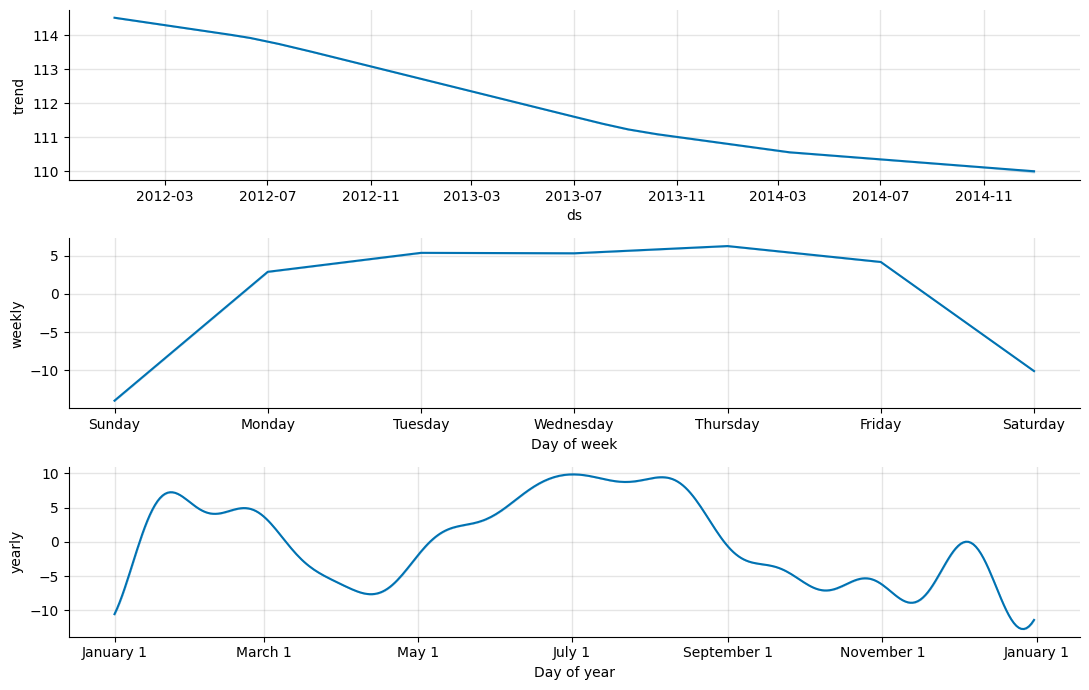

In [5]:
fig = m.plot_components(m.predict(elec[["ds"]]), figsize=(11, 7))      # drawn over 2012-2014
plt.show()

**📌 Що видно.**

- **Тиждень:** найтихіша неділя (≈ −14 ГВт·год від середнього), за нею субота. Робочі дні майже однакові.
- **Рік:** головний пік — **липень**, тобто зима. Опалення в Мельбурні важить більше, ніж кондиціонери: літній горбик у січні–лютому нижчий (+7 проти +10).
- **Різдво й Новий рік** видно навіть у річному сезоні: глибокий провал наприкінці грудня. Річна крива намагається зобразити свята, бо про них їй ніхто не сказав. Це завдання наступного кроку.
- **Тренд** за три роки опустився лише на 4 ГВт·год з ~114: дані майже пласкі, тренд тут не головний.

### 1.3 Свята: дні, коли календар ламається

У державне свято місто поводиться як у неділю, а тижневий сезон думає, що це четвер. Наскільки велика ця
помилка? Подивімося на похибки базової моделі на навчальних днях.

In [6]:
fit_e = m.predict(train_e[["ds"]])
residual = train_e["y"].to_numpy() - fit_e["yhat"].to_numpy()
on_holiday = train_e["holiday"].to_numpy()
print(f"звичайні дні: у середньому модель помиляється на {residual[~on_holiday].mean():+.1f} ГВт·год")
print(f"державні свята: у середньому модель перебільшує на {-residual[on_holiday].mean():.1f} ГВт·год")

звичайні дні: у середньому модель помиляється на +0.4 ГВт·год
державні свята: у середньому модель перебільшує на 12.8 ГВт·год


Prophet приймає свята як таблицю: назва і дата, а за бажанням — **вікно** днів навколо. Дамо кожному
святу Вікторії назву, а Різдву — вікно на шість днів після нього, бо тихий увесь тиждень між Різдвом і
Новим роком.

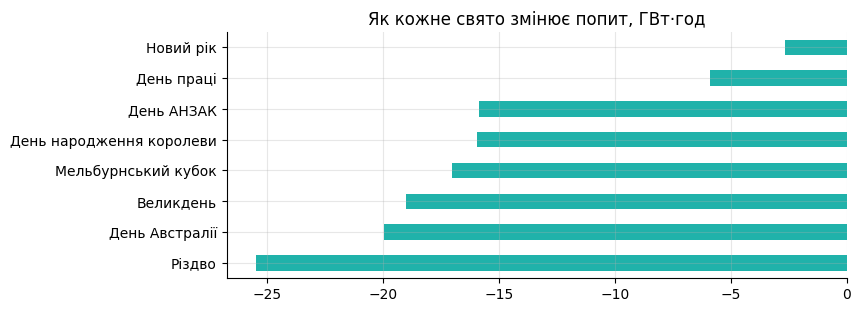

In [7]:
def holiday_name(d):
    if d.month == 1:
        return "Новий рік" if d.day <= 2 else "День Австралії"
    if d.month == 3 and d.day <= 14:
        return "День праці"
    if (d.month, d.day) == (4, 25):
        return "День АНЗАК"
    if d.month in (3, 4):
        return "Великдень"
    return {6: "День народження королеви", 11: "Мельбурнський кубок"}.get(d.month, "Різдво" if d.day == 25 else "День подарунків")


days_off = elec.loc[elec["holiday"], "ds"]
holidays = pd.DataFrame({"holiday": [holiday_name(d) for d in days_off], "ds": days_off.to_numpy(),
                         "lower_window": 0, "upper_window": 0})
holidays = holidays[holidays["holiday"] != "День подарунків"]                # Christmas's window covers it
holidays.loc[holidays["holiday"] == "Різдво", "upper_window"] = 6

m_hol = Prophet(daily_seasonality=False, holidays=holidays).fit(train_e[["ds", "y"]])
parts = m_hol.predict(train_e[["ds"]])
effect = pd.Series({name: parts.loc[train_e["ds"].isin(holidays.loc[holidays["holiday"] == name, "ds"]).to_numpy(), name].mean()
                    for name in holidays["holiday"].unique()}).sort_values()
effect.plot.barh(color=COLOURS["b"], figsize=(8, 3.2), title="Як кожне свято змінює попит, ГВт·год")
plt.show()

### 1.4 Температура: зовнішня змінна

U-подібна форма з першого графіка не може взятися з календаря. Prophet приймає додаткові стовпці через
`add_regressor`. Пряма лінія не зігнеться в літеру U, тож даємо температуру **і** її квадрат.

🔮 **Спершу вгадайте.** За якої температури попит найнижчий?

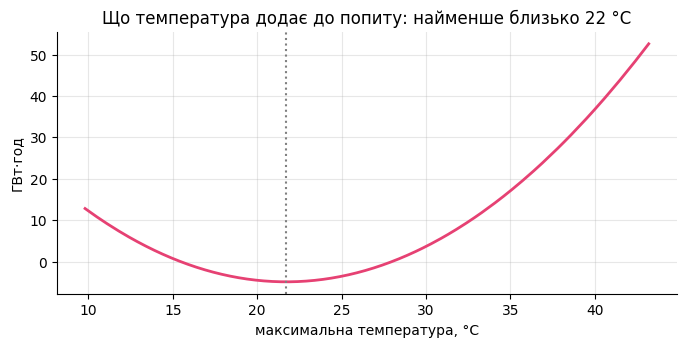

In [8]:
m_temp = Prophet(daily_seasonality=False, holidays=holidays)
m_temp.add_regressor("temp")
m_temp.add_regressor("temp2")
m_temp.fit(train_e[["ds", "y", "temp", "temp2"]])
parts = m_temp.predict(train_e[["ds", "temp", "temp2"]])

order = np.argsort(train_e["temp"].to_numpy())
curve = parts["extra_regressors_additive"].to_numpy()[order]
lowest = train_e["temp"].to_numpy()[order][np.argmin(curve)]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(train_e["temp"].to_numpy()[order], curve, color=COLOURS["a"], linewidth=2)
ax.axvline(lowest, color="grey", linestyle=":")
ax.set_xlabel("максимальна температура, °C")
ax.set_ylabel("ГВт·год")
ax.set_title(f"Що температура додає до попиту: найменше близько {lowest:.0f} °C")
plt.show()

### 1.5 Табло: Prophet проти старої гвардії

Дев'ять чотиритижневих вікон з квітня по грудень 2014. З одного боку — знайомі моделі:

- **сезонний наївний** — той самий день минулого тижня;
- **ETS** і **ARIMA** з $m = 7$ — лише один сезон;
- **MSTL** з обома сезонами, 7 і 365;
- **гармонічна регресія** — члени Фур'є для обох сезонів з ARIMA-похибками (тиждень 5): ідея Prophet,
  зроблена вручну;
- **гармонічна + погода** — те саме плюс температура, її квадрат і ознака свята.

З другого боку — Prophet, щоразу з однією можливістю більше, і одна чесна версія. Моделі з погодою беруть
температуру, яка **справді була**, — це прогноз ex post (тиждень 7). Четвертого грудня ніхто не знає,
якою буде температура тридцятого. Тож останній Prophet бере **клімат**: середню температуру того самого
тижня в попередні роки.

In [9]:
y1 = elec["y"].to_numpy()
t1 = np.arange(len(y1))
H1 = 28
origins1 = [len(y1) - H1 * k for k in range(9, 0, -1)]
labels1 = [f"{elec['ds'][e]:%d %b}" for e in origins1]
scale1 = np.mean(np.abs(y1[7:origins1[0]] - y1[:origins1[0] - 7]))      # seasonal naive MAE before the tests

X_season = np.column_stack([fourier(t1, 7, 3), fourier(t1, 365.25, 6)])
X_weather = np.column_stack([X_season, elec["temp"], elec["temp2"], elec["holiday"]])


def harmonic(X):
    return lambda e: AutoARIMA(season_length=1, d=0, max_p=3, max_q=3).fit(
        y=y1[:e], X=X[:e]).predict(h=H1, X=X[e:e + H1])["mean"]


def climate(e):
    # The forecaster's temperature on day e: the mean of the same calendar week in the years before.
    past = elec.iloc[:e]
    doy = past["ds"].dt.dayofyear.to_numpy()
    out = []
    for day in elec["ds"].iloc[e:e + H1].dt.dayofyear:
        gap = np.abs(doy - day)
        out.append(past["temp"].to_numpy()[np.minimum(gap, 365 - gap) <= 3].mean())
    return np.array(out)


def prophet_elec(with_holidays=False, weather=None):
    def forecast(e):
        model = Prophet(daily_seasonality=False, holidays=holidays if with_holidays else None)
        future = elec.iloc[e:e + H1].copy()
        if weather:
            model.add_regressor("temp")
            model.add_regressor("temp2")
            if weather == "climate":
                future["temp"] = climate(e)
                future["temp2"] = future["temp"] ** 2
        model.fit(elec.iloc[:e])
        return model.predict(future)["yhat"].to_numpy()
    return forecast


forecasters1 = {
    "seasonal naive": lambda e: np.tile(y1[e - 7:e], 4),
    "ETS (m = 7)": lambda e: AutoETS(season_length=7).fit(y=y1[:e]).predict(h=H1)["mean"],
    "ARIMA (m = 7)": lambda e: AutoARIMA(season_length=7).fit(y=y1[:e]).predict(h=H1)["mean"],
    "MSTL (7, 365)": lambda e: MSTL(season_length=[7, 365]).fit(y=y1[:e]).predict(h=H1)["mean"],
    "harmonic regression": harmonic(X_season),
    "harmonic + weather (actual)": harmonic(X_weather),
    "Prophet": prophet_elec(),
    "Prophet + holidays": prophet_elec(True),
    "Prophet + holidays + weather (actual)": prophet_elec(True, "actual"),
    "Prophet + holidays + weather (climate)": prophet_elec(True, "climate"),
}

🔮 **Спершу вгадайте.** Десять прогнозистів, дев'ять вікон. Розставте їх за місцями. Чи обіграє Prophet
MSTL? А гармонічну регресію, зібрану з тих самих деталей? Скільки виграшу від погоди лишиться, якщо погода
наперед невідома? (Близько двох хвилин.)

In [10]:
scores1, fc1 = backtest(y1, forecasters1, origins1, H1, scale1, labels1)
scoreboard(scores1)

,24 Apr,22 May,19 Jun,17 Jul,14 Aug,11 Sep,09 Oct,06 Nov,04 Dec,mean
seasonal naive,1.34,0.98,0.56,0.48,1.10,0.56,0.62,0.95,1.25,0.87
ETS (m = 7),0.74,0.80,0.53,0.48,1.03,0.45,0.37,1.01,1.12,0.73
ARIMA (m = 7),0.58,0.61,1.24,0.96,0.57,0.97,0.77,0.52,1.11,0.81
"MSTL (7, 365)",0.78,0.55,0.69,0.56,0.59,0.31,0.45,0.58,0.86,0.60
harmonic regression,0.71,1.05,0.35,0.47,0.35,0.40,0.41,0.52,0.95,0.58
harmonic + weather (actual),0.51,0.72,0.29,0.32,0.20,0.35,0.31,0.33,0.63,0.41
Prophet,0.69,0.60,0.56,0.79,0.38,0.40,0.37,0.55,0.91,0.58
Prophet + holidays,0.61,0.59,0.62,0.80,0.36,0.41,0.33,0.50,0.65,0.54
Prophet + holidays + weather (actual),0.44,0.30,0.41,0.65,0.27,0.31,0.34,0.39,0.52,0.40
Prophet + holidays + weather (climate),0.67,0.54,0.59,0.78,0.35,0.36,0.36,0.53,0.67,0.54


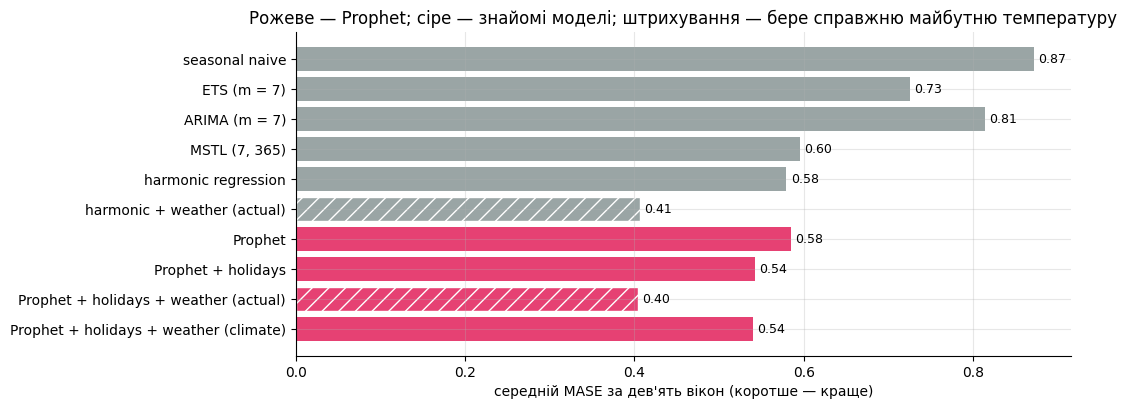

In [11]:
means = scores1["mean"].iloc[::-1]
colours = [COLOURS["a"] if n.startswith("Prophet") else COLOURS["old"] for n in means.index]
fig, ax = plt.subplots(figsize=(10, 4.2))
bars = ax.barh(means.index, means, color=colours)
for bar, name in zip(bars, means.index):
    if "(actual)" in name:
        bar.set_hatch("//")
        bar.set_edgecolor("white")
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xlabel("середній MASE за дев'ять вікон (коротше — краще)")
ax.set_title("Рожеве — Prophet; сіре — знайомі моделі; штрихування — бере справжню майбутню температуру")
plt.show()

**📌 Що показало табло.**

- **Prophet за замовчуванням (0,58)** — на рівні гармонічної регресії (0,58), трохи кращий за MSTL (0,60) і помітно кращий за ETS (0,73) та ARIMA (0,81) з одним сезоном. Два сезони перемагають один, хоч як їх моделювати.
- **Свята: 0,58 → 0,54.** Майже весь виграш — у грудневому вікні (0,91 → 0,65): саме туди потрапляють Різдво і тиждень після нього.
- **Погода, яка справді була: 0,40.** Це найбільший стрибок за весь кейс. У гармонічної регресії з погодою — **0,41, практично те саме**. Ті самі інгредієнти дають ту саму точність, хоч би в яку обгортку їх загорнули.
- **Погода з клімату: 0,54** — рівно стільки ж, скільки без погоди. Це логічно: «середня температура цього тижня» — це і є річний сезон, який модель уже знає.

Отже, виграш від температури — це виграш від **знання майбутньої погоди**. Без нього виграшу немає.

**❓ Питання.** Ви віддасте диспетчерові Prophet із погодою. Яку температуру ви підставите 4 грудня — і що
покажете замість однієї лінії?

**📌 Відповідь.** Справжній результат — десь між 0,54 і 0,40. На перші 5–7 днів метеопрогноз точний, і модель близька до 0,40. Далі він тане до кліматичної норми, а з ним і перевага.

Що робити на практиці:

- на перший тиждень підставляти **прогноз погоди**, далі — клімат;
- замість однієї лінії дати диспетчерові **сценарії**: «звичайний грудень», «спека 40 °C», «прохолодний тиждень». З кривої в 1.4 видно, що спека в 40 °C додає ≈ 40 ГВт·год на добу порівняно з комфортними 22 °C — більше, ніж будь-яке свято;
- пам'ятати, що 80% інтервал Prophet враховує шум, але не помилку в прогнозі температури.

## 2. 🍽️ Австралійці їдять поза домом: тренд Prophet

Місячний оборот усіх кафе, ресторанів і закладів їжі на винос Австралії, 1982–2018, млн $. Зовсім інший
ряд: сезон один, зате довгий тренд, що згинається, — рецесія на початку 1990-х, податок GST у 2000-му,
криза 2008-го.

Чи спрацює тут Prophet, вирішують два налаштування:

- `seasonality_mode` — грудневий пік додає фіксовану суму (**адитивний**, за замовчуванням) чи фіксовану
  частку (**мультиплікативний**)?
- `changepoint_prior_scale` — наскільки вільно тренд може змінювати нахил (за замовчуванням 0,05).

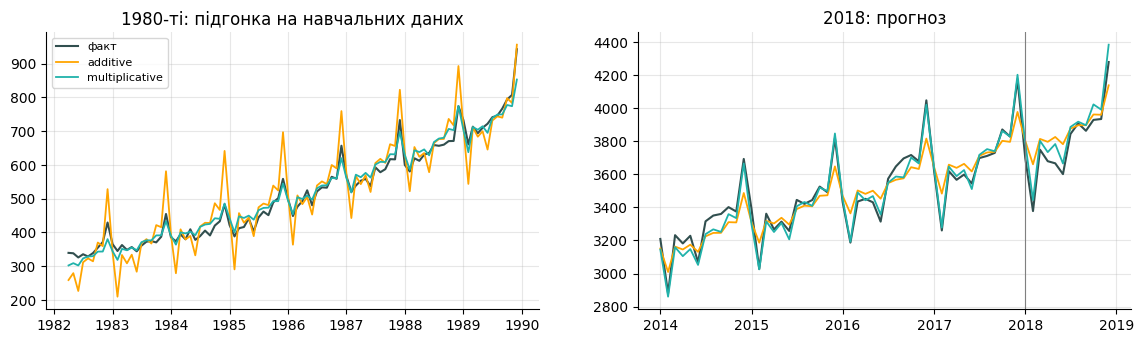

In [12]:
retail = pd.read_csv(f"{BASE}/aus_retail.csv", parse_dates=["Month"])
national = (retail.groupby(["Industry", "Month"], as_index=False)["Turnover"].sum()
            .rename(columns={"Industry": "unique_id", "Month": "ds", "Turnover": "y"}))
cafes = national.query("unique_id == 'Cafes, restaurants and takeaway food services'")[["ds", "y"]].reset_index(drop=True)
train_c, test_c = cafes.iloc[:-12], cafes.iloc[-12:]                  # 2018 is the test year


def prophet_cafes(**settings):
    return Prophet(weekly_seasonality=False, daily_seasonality=False, **settings)


fits = {mode: prophet_cafes(seasonality_mode=mode).fit(train_c) for mode in ("additive", "multiplicative")}
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, (start, end), title in [(axes[0], ("1982-04", "1989-12"), "1980-ті: підгонка на навчальних даних"),
                                (axes[1], ("2014-01", "2018-12"), "2018: прогноз")]:
    span = cafes[(cafes["ds"] >= start) & (cafes["ds"] <= end)]
    ax.plot(span["ds"], span["y"], color=COLOURS["actual"], linewidth=1.5, label="факт")
    for mode, colour in [("additive", COLOURS["c"]), ("multiplicative", COLOURS["b"])]:
        p = fits[mode].predict(span[["ds"]])
        ax.plot(p["ds"], p["yhat"], color=colour, linewidth=1.3, label=mode)
    ax.set_title(title)
axes[1].axvline(test_c["ds"].iloc[0], color="grey", linewidth=0.8)
axes[0].legend(fontsize=8)
plt.show()

Адитивний сезон — це компроміс між маленьким груднем 1985-го і великим 2017-го: завеликий на початку,
замалий у кінці. Мультиплікативний масштабується з рівнем — так само, як логарифм в ETS і ARIMA.

Тепер тренд. 🔮 **Спершу вгадайте.** Якщо тренд майже заморозити (0,001) або дуже розслабити (0,5), що
Prophet пророкуватиме на наступні п'ять років?

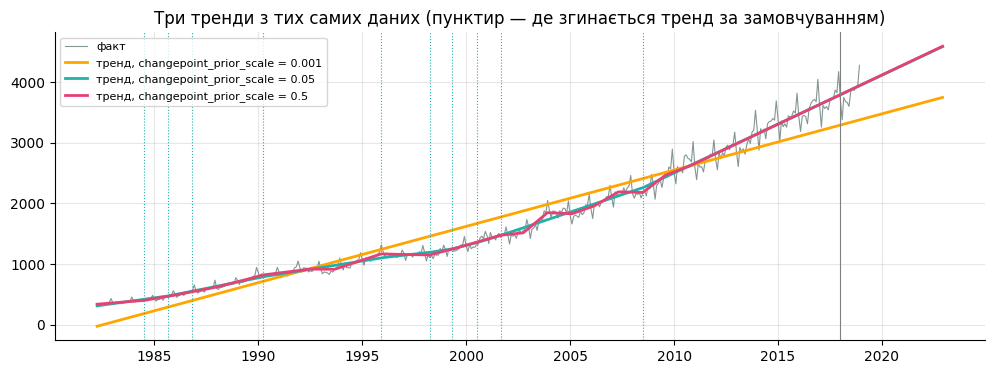

In [13]:
ahead = pd.DataFrame({"ds": pd.date_range(cafes["ds"].iloc[0], periods=len(train_c) + 60, freq="MS")})
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(cafes["ds"], cafes["y"], color=COLOURS["actual"], linewidth=0.8, alpha=0.6, label="факт")
for scale, colour in [(0.001, COLOURS["c"]), (0.05, COLOURS["b"]), (0.5, COLOURS["a"])]:
    model = prophet_cafes(seasonality_mode="multiplicative", changepoint_prior_scale=scale).fit(train_c)
    ax.plot(ahead["ds"], model.predict(ahead)["trend"], color=colour, linewidth=2,
            label=f"тренд, changepoint_prior_scale = {scale}")
    if scale == 0.05:
        bends = model.changepoints[np.abs(model.params["delta"]).mean(axis=0) > 0.01]
        for d in bends:
            ax.axvline(d, color=COLOURS["b"], linestyle=":", linewidth=0.8)
ax.axvline(test_c["ds"].iloc[0], color="grey", linewidth=0.8)
ax.set_title("Три тренди з тих самих даних (пунктир — де згинається тренд за замовчуванням)")
ax.legend(loc="upper left", fontsize=8)
plt.show()

Шість ковзних 12-місячних вікон, 2013–2018, проти моделей, які ви будували в лабораторних 5 і 7. ARIMA і
MSTL — з логарифмом, бо саме так їх узяв би уважний аналітик на цьому ряді.

In [14]:
y2 = cafes["y"].to_numpy()
H2 = 12
origins2 = [len(y2) - H2 * k for k in range(6, 0, -1)]
labels2 = [f"{cafes['ds'][e]:%Y}" for e in origins2]
scale2 = np.mean(np.abs(y2[12:origins2[0]] - y2[:origins2[0] - 12]))


def prophet_rolling(**settings):
    return lambda e: prophet_cafes(**settings).fit(cafes.iloc[:e]).predict(cafes.iloc[e:e + H2][["ds"]])["yhat"].to_numpy()


def logged(model):
    return lambda e: np.exp(model().fit(y=np.log(y2[:e])).predict(h=H2)["mean"])


forecasters2 = {
    "seasonal naive": lambda e: y2[e - 12:e],
    "ETS": lambda e: AutoETS(season_length=12).fit(y=y2[:e]).predict(h=H2)["mean"],
    "ARIMA (log)": logged(lambda: AutoARIMA(season_length=12)),
    "MSTL (log)": logged(lambda: MSTL(season_length=12)),
    "Prophet, defaults": prophet_rolling(),
    "Prophet, multiplicative": prophet_rolling(seasonality_mode="multiplicative"),
    "Prophet, multiplicative, loose trend (0.5)": prophet_rolling(seasonality_mode="multiplicative", changepoint_prior_scale=0.5),
    "Prophet, multiplicative, frozen trend (0.001)": prophet_rolling(seasonality_mode="multiplicative", changepoint_prior_scale=0.001),
}
scores2, fc2 = backtest(y2, forecasters2, origins2, H2, scale2, labels2)
scoreboard(scores2)

,2013,2014,2015,2016,2017,2018,mean
seasonal naive,1.33,2.99,1.29,1.62,1.42,1.15,1.63
ETS,0.78,0.90,0.54,0.63,0.50,0.51,0.64
ARIMA (log),0.51,0.41,0.46,0.41,0.67,0.67,0.52
MSTL (log),0.47,0.42,0.77,0.46,1.01,1.14,0.71
"Prophet, defaults",1.12,1.52,0.74,1.01,0.81,1.04,1.04
"Prophet, multiplicative",0.62,1.41,0.41,0.43,0.33,0.69,0.65
"Prophet, multiplicative, loose trend (0.5)",0.67,1.33,0.33,0.42,0.26,0.74,0.62
"Prophet, multiplicative, frozen trend (0.001)",4.07,5.72,5.37,5.59,5.42,5.00,5.20


**📌 Що показало табло.**

- **Prophet за замовчуванням (1,04) програє всім, крім сезонного наївного.** Адитивний сезон на ряді, що виріс удесятеро, — це помилка, яку видно ще на графіку 1980-х.
- **Одне слово `multiplicative`: 1,04 → 0,65.** Тепер Prophet на рівні ETS (0,64). У вікнах 2015–2017 він найкращий з усіх (0,41, 0,43, 0,33), а у 2014-му — один із найгірших (1,41).
- **Гнучкий тренд (0,5) ще трохи кращий (0,62).** Зате **заморожений (0,001) — катастрофа: 5,20.** Одна пряма через 35 років не влучає ні в 2013, ні в 2018 рік — подивіться на помаранчеву лінію на графіку трендів.
- **Найкращий — ARIMA на логарифмі (0,52).** Prophet із правильними налаштуваннями — пристойний учасник, але не переможець.

І ще одне з графіка трендів: Prophet ставить точки зламу лише в **перші 80% історії** (`changepoint_range = 0.8`). Нахил після 2009 року — одна пряма, і саме її він продовжує в майбутнє.

### Prophet в одній таблиці

| Prophet добре вміє | Слабкі місця Prophet |
|---|---|
| кілька сезонів одразу, будь-якої довжини (7, 365,25, 52,18) | не дивиться на останнє значення: вчорашній шок не пам'ятає |
| свята, з вікнами навколо них | тренд продовжується прямою, а його гнучкість — це здогадка |
| зовнішні змінні (температура, ціни, акції) | налаштування за замовчуванням: адитивний сезон, один фіксований `changepoint_prior_scale` |
| пропущені дні й нерегулярні дати | інтервал враховує лише шум і зміни тренду, а не хибний сезон |
| кожну частину можна намалювати й пояснити менеджерові | на звичайному місячному ряді добре підібрані ETS чи ARIMA зазвичай не гірші або кращі |

**❓ Питання.** Гармонічна регресія з погодою дала приблизно той самий результат, що й Prophet з погодою.
То що дав вам Prophet такого, чого не дала регресія?

**📌 Відповідь.** Не точність, а **зручність і прозорість**:

- свята з назвами й вікнами — однією таблицею, замість ручних дамі-змінних;
- регресор — одним рядком `add_regressor`, без збирання матриці членів Фур'є;
- графік компонентів, який можна показати диспетчерові чи менеджерові: «ось тиждень, ось рік, ось Різдво».

Але гармонічна регресія має те, чого немає в Prophet: **ARIMA-похибки**, тобто пам'ять про вчорашній день. На рядах, де шоки тривають кілька днів, це може переважити. Prophet — зручний конструктор, а не магія: точність дають інгредієнти (сезони, свята, погода), а не бібліотека.

# Частина 2. Комбінування прогнозів

## 3. 🍽️ Чотири прогнози на 2018 рік — і їхнє середнє

У першій частині кожна модель була учасником змагання, і ми обирали переможця. Тепер інша ідея, стара
як саме прогнозування (Бейтс і Грейнджер, 1969): **візьміть кілька пристойних прогнозів і усередніть їх.**

Чотири моделі, усі навчені на даних до грудня 2017: ETS, ARIMA і MSTL на логарифмі та мультиплікативний
Prophet з кейсу 2. Тест — 2018 рік.

🔮 **Спершу вгадайте.** Чи обіграє середнє чотирьох найкращу з них? Найгіршу? Де воно опиниться?

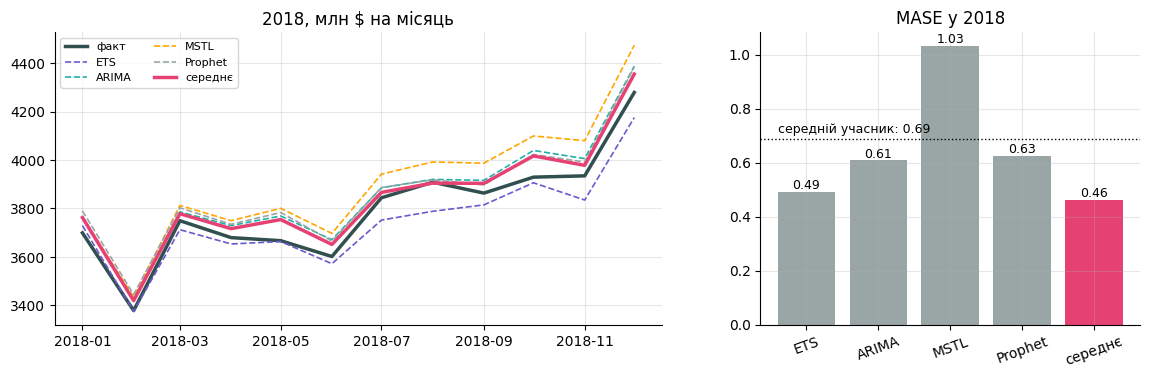

In [15]:
past_c = train_c["y"].to_numpy()
actual_c = test_c["y"].to_numpy()
scale_c = np.mean(np.abs(past_c[12:] - past_c[:-12]))


def on_log(model, history, h=12):
    return np.exp(model.fit(y=np.log(history)).predict(h=h)["mean"])


four = {
    "ETS": on_log(AutoETS(season_length=12), past_c),
    "ARIMA": on_log(AutoARIMA(season_length=12), past_c),
    "MSTL": on_log(MSTL(season_length=12), past_c),
    "Prophet": prophet_cafes(seasonality_mode="multiplicative").fit(train_c).predict(test_c[["ds"]])["yhat"].to_numpy(),
}
four["середнє"] = np.mean([four[n] for n in ("ETS", "ARIMA", "MSTL", "Prophet")], axis=0)
mase_c = pd.Series({n: np.mean(np.abs(actual_c - f)) / scale_c for n, f in four.items()})

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), width_ratios=[1.6, 1])
axes[0].plot(test_c["ds"], actual_c, color=COLOURS["actual"], linewidth=2.5, label="факт")
for (name, f), colour in zip(four.items(), [COLOURS["d"], COLOURS["b"], COLOURS["c"], COLOURS["old"], COLOURS["a"]]):
    axes[0].plot(test_c["ds"], f, color=colour, linewidth=2.5 if name.startswith("середнє") else 1.2,
                 linestyle="-" if name.startswith("середнє") else "--", label=name)
axes[0].set_title("2018, млн $ на місяць")
axes[0].legend(fontsize=8, ncol=2)
members_mean = mase_c.drop("середнє").mean()
bars = axes[1].bar(mase_c.index, mase_c, color=[COLOURS["old"]] * 4 + [COLOURS["a"]])
axes[1].bar_label(bars, fmt="%.2f", fontsize=9)
axes[1].axhline(members_mean, color="black", linestyle=":", linewidth=1)
axes[1].text(-0.4, members_mean * 1.03, f"середній учасник: {members_mean:.2f}", fontsize=9)
axes[1].set_title("MASE у 2018")
axes[1].tick_params(axis="x", labelrotation=20)
plt.show()

Чому це працює? Кожна модель помиляється по-своєму: одна перестрибує грудень, інша недотягує березень. У
середньому похибки протилежного знаку **гасять одна одну**. І одна гарантія виконується завжди, для
будь-якого ряду:

$$\Big|\,y - \tfrac{1}{k}\textstyle\sum_i \hat y_i\Big| \;\le\; \tfrac{1}{k}\textstyle\sum_i |y - \hat y_i|,$$

тож MAE комбінації **ніколи не гірший за MAE середнього учасника** (пунктирна лінія). Він може бути
гіршим за найкращого учасника — але хто буде найкращим, ви наперед не знаєте.

**📌 Що сталося.**

- **Середнє (0,46) обіграло всіх чотирьох**, зокрема найкращу ETS (0,49). Так буває не завжди, але тут видно чому: ETS із середини року **недооцінює** (фіолетова лінія нижче факту), а MSTL, ARIMA і Prophet **переоцінюють**. У середньому ці помилки гасять одна одну.
- **MSTL (1,03)** — найгірший учасник, але середнє він не зіпсував: 0,46 проти 0,69 у середнього учасника.
- Гарантія з формули — «не гірше за 0,69». Усе, що краще, — бонус від того, що моделі помиляються **по-різному**.

## 4. 🏨 76 туристичних регіонів: обрати чи усереднити?

«Але ж я *можу* дізнатися, хто найкращий, — скажете ви. — Перевірю на валідаційних вікнах і візьму
переможця». Перевіримо саме це — не на одному ряді, де все вирішує везіння, а на 76.

Квартальна кількість поїздок із ночівлею до кожного з 76 туристичних регіонів Австралії, 1998–2017. Для
кожного регіону:

- **обрати** — оцінити ETS, ARIMA і Theta на трьох валідаційних вікнах і взяти переможця на тест;
- **усереднити** — середнє трьох, нічого не обираючи.

Тест — останні два роки (8 кварталів), яких не бачив жоден із підходів.

In [16]:
tourism = pd.read_csv(f"{BASE}/tourism.csv", parse_dates=["ds"])
regions = tourism.groupby(["Region", "ds"], as_index=False)["y"].sum().rename(columns={"Region": "unique_id"})
H4 = 8
test4 = regions.groupby("unique_id").tail(H4)
train4 = regions.drop(test4.index)
names4 = ["ETS", "ARIMA", "Theta"]
sf4 = StatsForecast(models=[AutoETS(season_length=4, alias="ETS"), AutoARIMA(season_length=4, alias="ARIMA"),
                            AutoTheta(season_length=4, alias="Theta"), SeasonalNaive(4, alias="seasonal naive")],
                    freq="QS", n_jobs=-1)
validation = sf4.cross_validation(df=train4, h=H4, n_windows=3, step_size=4)       # three origins, a year apart
tested = sf4.forecast(df=train4, h=H4).merge(test4, on=["unique_id", "ds"])
scale4 = train4.groupby("unique_id")["y"].apply(lambda s: np.mean(np.abs(s.to_numpy()[4:] - s.to_numpy()[:-4])))


def mase_by_region(df, columns):
    return df.groupby("unique_id").apply(
        lambda g: pd.Series({c: np.mean(np.abs(g["y"] - g[c])) for c in columns}), include_groups=False
    ).div(scale4, axis=0)


tested["середнє трьох"] = tested[names4].mean(axis=1)
val4 = mase_by_region(validation, names4)
test_scores4 = mase_by_region(tested, names4 + ["seasonal naive", "середнє трьох"])
picked = val4.idxmin(axis=1)
test_scores4["вибір на валідації"] = [test_scores4.loc[r, picked[r]] for r in test_scores4.index]
test_scores4["оракул: знає переможця тесту"] = test_scores4[names4].min(axis=1)

🔮 **Спершу вгадайте.** З трьох кандидатів монетка вгадує переможця тесту в одному випадку з трьох. Як
часто його вгадує валідація?

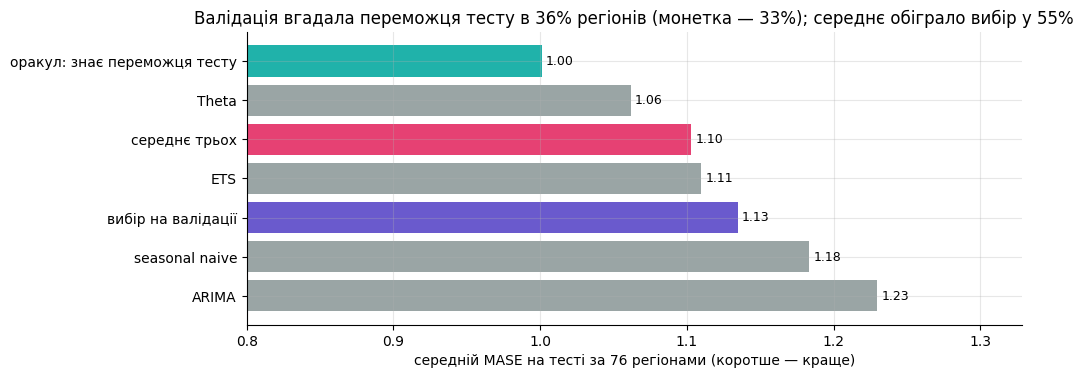

In [17]:
hit = (picked == test_scores4[names4].idxmin(axis=1)).mean()
avg_wins = (test_scores4["середнє трьох"] < test_scores4["вибір на валідації"]).mean()

means4 = test_scores4.mean().sort_values(ascending=False)
colours = [COLOURS["a"] if n == "середнє трьох" else COLOURS["d"] if n.startswith("вибір")
           else COLOURS["b"] if n.startswith("оракул") else COLOURS["old"] for n in means4.index]
fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.barh(means4.index, means4, color=colours)
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xlim(0.8, means4.max() * 1.08)
ax.set_xlabel("середній MASE на тесті за 76 регіонами (коротше — краще)")
ax.set_title(f"Валідація вгадала переможця тесту в {hit:.0%} регіонів (монетка — 33%); "
             f"середнє обіграло вибір у {avg_wins:.0%}")
plt.show()

**📌 Що показав експеримент.**

- **Валідація вгадала переможця тесту в 36% регіонів — монетка вгадала б у 33%.** Три пристойні моделі на трьох вікнах — це здебільшого шум: хто виграв валідацію, вирішує випадок.
- **Середнє (1,10) краще за вибір (1,13)** і обіграє його в 55% регіонів. Виграш невеликий, але безкоштовний: нічого не треба обирати.
- **Оракул (1,00)** — недосяжна межа, бо він знає майбутнє. Середнє закриває приблизно чверть розриву між вибором і оракулом.
- **Theta (1,06)** — найкраща окрема модель на цих даних. Про це — питання нижче.

**❓ Питання.** Сама лише Theta впоралася краще за обидві стратегії. То, може, завжди брати Theta? Що
треба було знати у 2015 році, щоб ухвалити таке рішення?

**📌 Відповідь.** Ні, це рішення **заднім числом**. Ми знаємо, що Theta найкраща, лише тому, що вже бачили тест. На трьох валідаційних вікнах вона вигравала далеко не скрізь: вибір брав її лише в третині регіонів.

Виправдано було б обрати Theta **наперед**, на підставі знань ззовні: Theta виграла змагання M3 і сильна на квартальних і річних даних. Це аргумент, а не підгонка під тест.

Найпростіший компроміс — **додати Theta до середнього**, а не ставити лише на неї.

## 5. 🍽️ Рецепт Lab 8 крок за кроком

Повертаємося до кафе і робимо рівно те, що ви сьогодні робитимете на власному ряді:

1. **Учасники.** ETS, ARIMA і MSTL — обрані **до того**, як ви побачили хоч одну оцінку.
2. **Ковзні вікна.** Кожен учасник прогнозує чотири 12-місячні вікна перед тестом (2014–2017).
3. **Читаємо таблицю.** Хто виграє яке вікно? Наскільки комбінація близька до найкращого?
4. **Інтервал.** Два рецепти, кожен перевірений на вікні, якого він не бачив.
5. **Здаємо.** Перенавчаємо на всьому, усереднюємо, додаємо інтервал — і дивимося, як пройшов 2018-й.

Допоміжні функції нижче — ті самі, що в шаблоні Lab 8.

In [18]:
MEMBERS = {"ETS": lambda: AutoETS(season_length=12), "ARIMA": lambda: AutoARIMA(season_length=12),
           "MSTL": lambda: MSTL(season_length=12)}                      # all three on the log scale
WINDOWS, H5 = 4, 12


def member_forecast(make, history, h=H5):
    out = make().fit(y=np.log(history)).predict(h=h, level=[80])
    return {k: np.exp(v) for k, v in out.items()}


def backtest_members(history, windows=WINDOWS, h=H5):
    # One row per (window, step): the actual value and every member's forecast and 80% bounds.
    frames = []
    for k in range(windows, 0, -1):
        end = len(history) - (k - 1) * h
        past, actual = history[:end - h], history[end - h:end]
        frame = pd.DataFrame({"window": k, "step": np.arange(1, h + 1), "actual": actual})
        for name, make in MEMBERS.items():
            fc = member_forecast(make, past, h)
            frame[name], frame[f"{name} lo"], frame[f"{name} hi"] = fc["mean"], fc["lo-80"], fc["hi-80"]
        frames.append(frame)
    bt = pd.concat(frames, ignore_index=True)
    bt["combination"] = bt[list(MEMBERS)].mean(axis=1)
    bt["combination lo"] = bt[[f"{n} lo" for n in MEMBERS]].mean(axis=1)
    bt["combination hi"] = bt[[f"{n} hi" for n in MEMBERS]].mean(axis=1)
    return bt


def winkler(actual, lo, hi, alpha=0.2):
    # Width plus 2/alpha times every miss, in units of the MASE scale.
    return float(np.mean((hi - lo) + 2 / alpha * (np.maximum(lo - actual, 0) + np.maximum(actual - hi, 0))) / scale_c)


def conformal_radius(errors):
    # 80% of the past absolute errors were smaller than this: forecast +- radius is the 80% interval.
    return float(np.quantile(np.abs(errors), 0.80))


bt = backtest_members(past_c)
columns = list(MEMBERS) + ["combination"]
table5 = bt.groupby("window").apply(
    lambda g: pd.Series({c: np.mean(np.abs(g["actual"] - g[c])) / scale_c for c in columns}), include_groups=False).T
table5 = table5[sorted(table5.columns, reverse=True)]                    # oldest window first
table5.columns = [f"window {w}: {2018 - w}" for w in table5.columns]
table5["mean"] = table5.mean(axis=1)

🔮 **Спершу вгадайте.** Чотири вікна, три учасники. Чи виграє один учасник усі чотири? Де буде комбінація
в кожному?

In [19]:
scoreboard(table5)

,window 4: 2014,window 3: 2015,window 2: 2016,window 1: 2017,mean
ETS,0.38,0.60,1.13,0.69,0.70
ARIMA,0.37,0.41,0.37,0.61,0.44
MSTL,0.38,0.69,0.42,0.91,0.60
combination,0.37,0.56,0.48,0.73,0.54


In [20]:
errors = bt[list(MEMBERS)].rsub(bt["actual"], axis=0)
print("наскільки схожі похибки учасників (кореляція):")
print(errors.corr().round(2))

наскільки схожі похибки учасників (кореляція):
        ETS  ARIMA  MSTL
ETS    1.00   0.82  0.66
ARIMA  0.82   1.00  0.90
MSTL   0.66   0.90  1.00


**📌 Що в таблиці.**

- **Цього разу один учасник виграв усі вікна — ARIMA** (0,37 / 0,41 / 0,37 / 0,61; у 2014 році всі майже рівні). Середнє ARIMA 0,44 проти 0,54 у комбінації. Валідація каже: «беріть ARIMA».
- **Комбінація ніде не найгірша**: у 2016 році ETS провалилася (1,13), а комбінація втрималася на 0,48.
- **Кореляції похибок — від 0,66 до 0,90.** ARIMA і MSTL помиляються майже однаково (0,90), ETS і MSTL — найбільш по-різному (0,66). Найбільше від усереднення можна виграти саме на цій парі.

🔮 Запам'ятайте, що радить валідація, — і подивіться на 2018 рік нижче.

**Інтервал.** Власні інтервали учасників нічого не знають один про одного, і кожен вірить, що його модель
правильна. Два рецепти:

- **усереднені межі** — середнє нижніх меж учасників і середнє верхніх;
- **conformal** — беремо похибки комбінації на вікнах, знаходимо розмір, якого не перевищили 80% із них,
  і відкладаємо цей радіус по обидва боки від нового прогнозу. Жодних припущень про модель — лише «майбутні
  похибки будуть схожі на минулі».

Щоб судити чесно, кожне вікно по черзі відкладаємо: conformal-радіус для вікна 1 рахуємо лише з вікон
2–4. Інакше рецепт перевіряв би сам себе.

In [21]:
rows = []
for w, g in bt.groupby("window"):
    others = bt[bt["window"] != w]
    r = conformal_radius(others["actual"] - others["combination"])
    for recipe, lo, hi in [("усереднені межі", g["combination lo"], g["combination hi"]),
                           ("conformal", g["combination"] - r, g["combination"] + r)]:
        rows.append({"recipe": recipe, "coverage": np.mean((g["actual"] >= lo) & (g["actual"] <= hi)),
                     "Winkler": winkler(g["actual"], lo, hi), "width": np.mean(hi - lo) / scale_c})
interval_check = pd.DataFrame(rows).groupby("recipe").mean()
scoreboard(interval_check, rules={"coverage": 0.8, "Winkler": "lower", "width": "lower"})

,coverage,Winkler,width
conformal,0.75,2.29,1.52
усереднені межі,1.00,3.46,3.46


🔮 **Спершу вгадайте.** Тепер по-справжньому: перенавчаємо на всьому до грудня 2017 і прогнозуємо 2018.
Чи обіграє комбінація учасника, що виграв валідаційну таблицю? Який інтервал утримає 2018-й?

In [22]:
final = {name: member_forecast(make, past_c) for name, make in MEMBERS.items()}
combo = np.mean([final[n]["mean"] for n in MEMBERS], axis=0)
radius = conformal_radius(bt["actual"] - bt["combination"])               # now from all four windows
intervals = {"усереднені межі": (np.mean([final[n]["lo-80"] for n in MEMBERS], axis=0),
                                 np.mean([final[n]["hi-80"] for n in MEMBERS], axis=0)),
             "conformal": (combo - radius, combo + radius)}
winner = table5.loc[list(MEMBERS), "mean"].idxmin()

test_table = pd.DataFrame({
    "MASE": {**{n: np.mean(np.abs(actual_c - final[n]["mean"])) / scale_c for n in MEMBERS},
             "combination": np.mean(np.abs(actual_c - combo)) / scale_c}})
test_table.loc[f"вибір на валідації ({winner})"] = test_table.loc[winner, "MASE"]
display(scoreboard(test_table))
scoreboard(pd.DataFrame({k: {"coverage": np.mean((actual_c >= lo) & (actual_c <= hi)),
                             "Winkler": winkler(actual_c, lo, hi), "width": np.mean(hi - lo) / scale_c}
                         for k, (lo, hi) in intervals.items()}).T,
           rules={"coverage": 0.8, "Winkler": "lower", "width": "lower"})

,MASE
ETS,0.49
ARIMA,0.61
MSTL,1.03
combination,0.41
вибір на валідації (ARIMA),0.61


,coverage,Winkler,width
усереднені межі,1.00,3.89,3.89
conformal,0.92,1.57,1.52


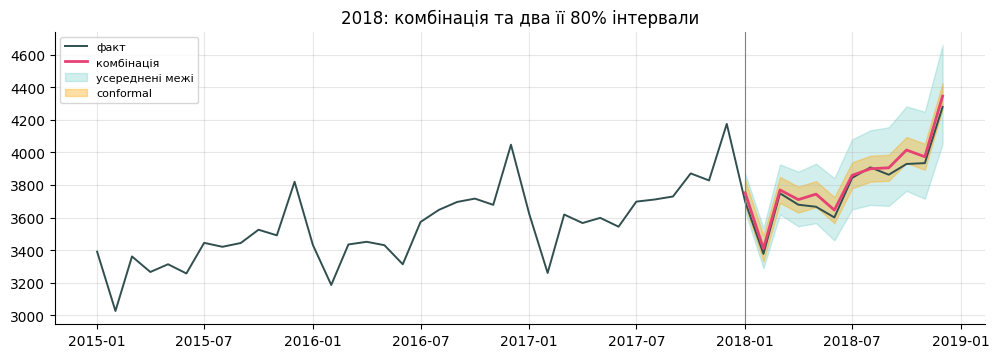

In [23]:
fig, ax = plt.subplots(figsize=(12, 3.8))
recent = cafes.iloc[-48:]
ax.plot(recent["ds"], recent["y"], color=COLOURS["actual"], linewidth=1.4, label="факт")
ax.plot(test_c["ds"], combo, color=COLOURS["a"], linewidth=2, label="комбінація")
for (name, (lo, hi)), colour, alpha in zip(intervals.items(), [COLOURS["b"], COLOURS["c"]], [0.2, 0.35]):
    ax.fill_between(test_c["ds"], lo, hi, color=colour, alpha=alpha, label=name)
ax.axvline(test_c["ds"].iloc[0], color="grey", linewidth=0.8)
ax.set_title("2018: комбінація та два її 80% інтервали")
ax.legend(loc="upper left", fontsize=8)
plt.show()

**📌 Що сталося у 2018 році.**

- **Переможець валідації, ARIMA, у тесті лише третій (0,61).** Комбінація — перша (0,41), за нею ETS (0,49), яка на валідації була найгіршою. Саме від цього комбінація і страхує: чотири виграні вікна не гарантують п'ятого.
- **Інтервали на відкладених вікнах:** усереднені межі покрили 100% при ширині 3,46 — вони просто завширокі. Conformal покрив 75%, удвічі вужчий (1,52) і має кращий Вінклер (2,29 проти 3,46).
- **У 2018 році** conformal покрив 92% місяців, Вінклер 1,57 проти 3,89. На графіку помаранчева смуга щільно облягає факт, а бірюзова вдвічі ширша.
- Радіус conformal стоїть на 48 похибках (4 вікна × 12 місяців). Для одного ряду це небагато: 92% замість 80% цілком у межах шуму.

**❓ Питання.** Ваш ряд для Lab 8 — не кафе. Які з сьогоднішніх рішень ви ухвалюєте **до** того, як
побачите свою таблицю, — які учасники, логарифм чи ні, чи комбінувати взагалі, — а які вирішує таблиця?

**📌 Відповідь.**

**До таблиці:**

- **учасники** — ваші ETS з Lab 5 і ARIMA з Lab 7, з MSTL чи без нього. Чи включати MSTL, вирішуйте за аргументом, а не за таблицею: його не відбирали для пулу, тож він може зламатися;
- **логарифм** — за тим, чи росте сезонний розмах. Ви це вже знаєте з минулих лабораторних;
- **комбінувати** — так. Кейси 3–5 показують, що це дешева страховка.

**За таблицею:**

- чи немає учасника, **зламаного в кожному вікні** (MASE у рази гірший за бенчмарк);
- **який інтервал** — за перевіркою на відкладених вікнах;
- **чого чекати** — з поправкою на те, що чотири вікна шумні, а ваші моделі вже налаштовані на цих даних.

**Чого не робити:** викидати учасника лише тому, що він програв таблицю. Тоді ви знову обираєте, просто приховано.

## Що взяти з собою на сьогоднішню лабораторну

- **Prophet** — це підгонка кривої з добрими деталями: кілька сезонів, свята, зовнішні змінні. Його
  налаштування за замовчуванням можуть зіпсувати місячний ряд. Вмикайте те, що потрібно ряду, і
  перевіряйте на ковзних вікнах, як будь-яку іншу модель.
- **Середнє** кількох пристойних моделей ніколи не гірше за середнього учасника, а на більшості рядів
  близьке до найкращого — і не треба вгадувати, хто ним буде.
- **Вибір на валідації** шумніший, ніж здається: три вікна кажуть менше, ніж вам хочеться.
- **Інтервал** слід перевіряти на даних, яких він не бачив. Conformal простий і чесний щодо власної
  історії помилок.

**Lab 8** — це кейс 5 на вашому власному ряді Track B, з вашою ETS з лабораторної 5 і ARIMA з
лабораторної 7.